In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_final.csv")
df['tle_epoch'] = pd.to_datetime(df['tle_epoch'])
df['target_epoch'] = pd.to_datetime(df['target_epoch'])
df = df.sort_values(['tle_epoch', 'days_offset']).reset_index(drop=True)

omega = np.array([0.0, 0.0, 7.292115e-5])            # rad/s
r = df[['x', 'y', 'z']].values
v_in = df[['vx', 'vy', 'vz']].values + np.cross(omega, r)   # prędkość inercjalna w osiach ECEF
e = df[['x_error', 'y_error', 'z_error']].values

R = r / np.linalg.norm(r, axis=1, keepdims=True)
N = np.cross(r, v_in)
N /= np.linalg.norm(N, axis=1, keepdims=True)
T = np.cross(N, R)

df['r_error'] = np.sum(e * R, axis=1)
df['t_error'] = np.sum(e * T, axis=1)
df['n_error'] = np.sum(e * N, axis=1)

In [2]:
rtn = ['r_error', 't_error', 'n_error']

# 1. długość zachowana
print(np.allclose(np.linalg.norm(df[rtn].values, axis=1), np.linalg.norm(e, axis=1)))

# 2. czy t_error dominuje i rośnie z wiekiem
print(df.groupby('days_offset')[rtn].agg(lambda s: s.abs().median()).round(2))

# 3. czy t_error ma stały znak (kluczowe dla baseline'u medianowego)
print(df.groupby('days_offset')['t_error'].agg(
    mediana='median',
    dodatnie=lambda s: (s > 0).mean()).round(2))

True
             r_error  t_error  n_error
days_offset                           
0               0.45     1.09     0.18
1               0.44     1.06     0.22
2               0.50     0.98     0.28
3               0.57     1.03     0.36
4               0.65     1.27     0.44
5               0.77     1.96     0.54
6               0.90     3.08     0.64
7               1.02     4.42     0.71
8               1.13     5.97     0.80
9               1.17     7.37     0.88
10              1.27     9.02     0.94
             mediana  dodatnie
days_offset                   
0              -0.10      0.46
1               0.05      0.52
2               0.28      0.57
3               0.43      0.61
4               0.30      0.58
5               0.18      0.52
6               0.18      0.51
7               0.05      0.50
8              -0.10      0.50
9              -0.55      0.48
10             -0.65      0.48


In [3]:
df.to_csv("cleaned_rtn.csv", index=False)

In [10]:
def split(df, start, end, gap_days=10):
    test = df[(df['tle_epoch'] >= start) & (df['tle_epoch'] < end)]
    train = df[df['tle_epoch'] < pd.Timestamp(start) - pd.Timedelta(days=gap_days)]
    return train, test

def stat(x):
    return x.mean(), np.median(x), np.percentile(x, 90)

windows = [('2025-03-01', '2025-05-01'), ('2025-05-01', '2025-07-01'),
           ('2025-07-01', '2025-09-01'), ('2025-09-01', '2025-11-20')]

rows = []
for a, b in windows:
    tr, te = split(df, a, b)
    med = tr.groupby('days_offset')[rtn].median()
    pred = med.loc[te['days_offset'].values].values       # korekta RTN z mediany per offset
    true = te[rtn].values

    e_sgp4 = np.linalg.norm(true, axis=1)
    e_med  = np.linalg.norm(true - pred, axis=1)
    pred_t = pred * np.array([0, 1, 0])                    # korekta tylko w t_error
    e_med_t = np.linalg.norm(true - pred_t, axis=1)

    for name, ee in [('SGP4', e_sgp4), ('mediana RTN', e_med), ('mediana tylko T', e_med_t)]:
        s = stat(ee)
        rows.append(dict(okno=f"{a}..{b}", metoda=name,
                         srednia=s[0], mediana=s[1], p90=s[2]))

print(pd.DataFrame(rows).round(3).to_string(index=False))

                  okno          metoda  srednia  mediana    p90
2025-03-01..2025-05-01            SGP4    3.271    1.974  7.662
2025-03-01..2025-05-01     mediana RTN    3.290    2.020  7.820
2025-03-01..2025-05-01 mediana tylko T    3.282    1.985  7.838
2025-05-01..2025-07-01            SGP4    3.369    2.098  8.318
2025-05-01..2025-07-01     mediana RTN    3.453    2.232  8.478
2025-05-01..2025-07-01 mediana tylko T    3.403    2.155  8.480
2025-07-01..2025-09-01            SGP4    3.449    2.230  8.302
2025-07-01..2025-09-01     mediana RTN    3.427    2.186  8.240
2025-07-01..2025-09-01 mediana tylko T    3.432    2.186  8.366
2025-09-01..2025-11-20            SGP4    4.586    2.649 11.394
2025-09-01..2025-11-20     mediana RTN    4.535    2.539 11.564
2025-09-01..2025-11-20 mediana tylko T    4.581    2.651 11.577


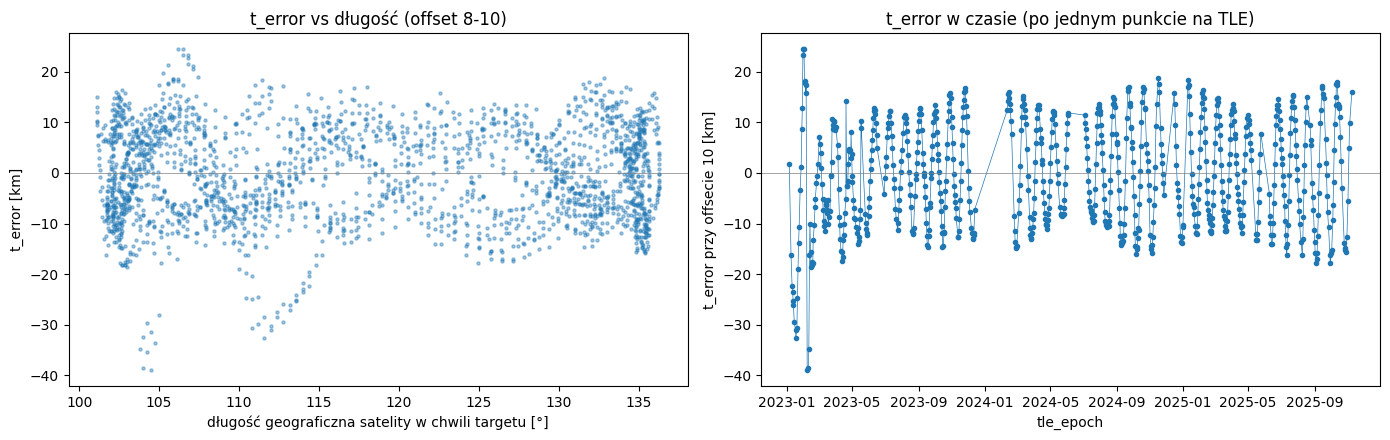

In [11]:
late = df[df['days_offset'] >= 8].copy()
late['lon'] = np.degrees(np.arctan2(late['y'], late['x']))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. czy znak t_error zależy od długości geograficznej?
ax[0].scatter(late['lon'], late['t_error'], s=5, alpha=0.4)
ax[0].axhline(0, color='gray', lw=0.5)
ax[0].set_xlabel('długość geograficzna satelity w chwili targetu [°]')
ax[0].set_ylabel('t_error [km]'); ax[0].set_title('t_error vs długość (offset 8-10)')

# 2. czy znak t_error zależy od czasu (kolejne TLE podobne)?
d10 = df[df['days_offset'] == 10].sort_values('tle_epoch')
ax[1].plot(d10['tle_epoch'], d10['t_error'], '.-', lw=0.5)
ax[1].axhline(0, color='gray', lw=0.5)
ax[1].set_xlabel('tle_epoch'); ax[1].set_ylabel('t_error przy offsecie 10 [km]')
ax[1].set_title('t_error w czasie (po jednym punkcie na TLE)')
plt.tight_layout(); plt.show()